# The Harvard Forest inverse problem

This notebook introduces the inverse problem that the algorithms built in this repository
seek to solve: calibrating the SIPNET land-surface model against measurements of carbon
fluxes at Harvard Forest. Each section introduces one part of the problem, shows how to work
with it in code, and visualizes it. The full mathematical statement of the problem is in the
last section. The mathematical notation follows the repo conventions in
[`docs/notation.md`](../docs/notation.md).

Running the whole notebook takes about a minute (it runs SIPNET about 320 times).

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from probpipe import (
    NumericArrayBatch,
    log_prob,
    marginal,
    quantile,
    sample,
    summarize,
    unnormalized_log_prob,
    workflow_run,
)
from pysipnet import ClimateDrivers

from lsmas import plots
from lsmas.data import load_harvard_forest
from lsmas.parameters import calibration_to_sipnet
from lsmas.priors import prior_medians
from lsmas.problems import load
from lsmas.sipnet import SIPNETSimulator

YEAR = 2015  # the year that the one-year figures show

The next cell defines the plotting functions this notebook uses. It is collapsed; expand it to see
how a figure is drawn.

In [2]:
CLASS_COLOURS = {"day": "tab:orange", "night": "tab:blue"}
NEE_UNITS = "µmol m⁻² s⁻¹"


def features_in_class(data, feature_class, year=None):
    """The indices of the data values of one class (and one year, if given), in time order."""
    keep = data.feature_classes == feature_class
    if year is not None:
        keep &= data.feature_times.year == year
    rows = np.flatnonzero(keep)
    return rows[np.argsort(data.feature_times[rows])]


def daily(series):
    """Daily values of a three-hourly variable: totals over a step are summed, others averaged."""
    by_day = series.resample(time="1D")
    return by_day.sum() if series.attrs.get("kind") == "timestep_total" else by_day.mean()


def plot_weather(driver, year):
    """Daily air temperature, light, vapor pressure deficit and precipitation for one year."""
    one_year = driver.sel(time=str(year))
    panels = {
        "air temperature (°C)": daily(one_year["air_temperature"]),
        "PAR (mol m⁻² d⁻¹)": daily(one_year["photosynthetically_active_radiation"]),
        "VPD (kPa)": daily(one_year["vapor_pressure_deficit"]) / 1000,
        "precipitation (mm d⁻¹)": daily(one_year["precipitation"]),
    }
    figure, axes = plt.subplots(len(panels), 1, figsize=(9, 6.5), sharex=True)
    for axis, (label, series) in zip(axes, panels.items(), strict=True):
        axis.plot(series["time"], series, lw=0.8)
        axis.set_ylabel(label, fontsize=8)
    figure.suptitle(f"The weather at Harvard Forest, {year}")


def plot_predictions(data, predictions, labels=None):
    """The observed data (dots) and one or more predictions of them (lines), by class."""
    predictions = np.atleast_2d(predictions)
    times = data.feature_times
    _, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    for axis, feature_class in zip(axes, CLASS_COLOURS, strict=True):
        rows = features_in_class(data, feature_class)
        for index, prediction in enumerate(predictions):
            label = None if labels is None else labels[index]
            axis.plot(times[rows], prediction[rows], lw=0.9, alpha=0.8, label=label)
        axis.plot(times[rows], data.observations[rows], ".k", ms=3, label="observed")
        axis.axhline(0, color="0.3", lw=0.5)
        axis.set_ylabel(f"{feature_class} NEE ({NEE_UNITS})", fontsize=8)
    axes[0].legend(fontsize=7, loc="lower right")


def plot_one_at_a_time(data, predictions, parameter_names, levels, year):
    """Predictions for one year as each parameter moves through its prior quantiles."""
    times = data.feature_times
    colours = plt.cm.viridis(np.linspace(0, 1, len(levels)))
    shape = (len(parameter_names), len(levels), -1)
    predictions = predictions.reshape(shape)
    figure, axes = plt.subplots(2, len(parameter_names), figsize=(13, 5), sharex=True)
    for column, name in enumerate(parameter_names):
        for row, feature_class in enumerate(CLASS_COLOURS):
            rows = features_in_class(data, feature_class, year)
            axis = axes[row, column]
            for index, level in enumerate(levels):
                prediction = predictions[column, index, rows]
                axis.plot(times[rows], prediction, color=colours[index], label=f"{level:.1%}")
            axis.plot(times[rows], data.observations[rows], ".k", ms=3)
            axis.set_title(f"{name} ({feature_class})", fontsize=7)
            axis.tick_params(labelsize=6)
    axes[0, 0].legend(fontsize=6, title="prior quantile", title_fontsize=6)
    figure.suptitle(f"One parameter at a time through its prior, the rest at their medians, {year}")
    figure.tight_layout()


def plot_sipnet_outputs(outputs, nee_rate, step_ends, year):
    """SIPNET's NEE, GPP, leaf carbon and soil wetness through one year."""
    nee = pd.Series(nee_rate, index=step_ends)[str(year)]
    one_year = outputs.sel(time=str(year))
    figure, axes = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
    axes[0].plot(nee.index, nee, lw=0.3, color="0.6", label="three-hourly")
    axes[0].plot(nee.resample("1D").mean(), lw=1, label="daily mean")
    axes[0].axhline(0, color="k", lw=0.5)
    axes[0].set_ylabel(f"NEE ({NEE_UNITS})", fontsize=8)
    axes[0].legend(fontsize=7)
    for axis, name, label in [
        (axes[1], "gross_primary_production", "GPP (g C m⁻² d⁻¹)"),
        (axes[2], "leaf_carbon", "leaf carbon (g C m⁻²)"),
        (axes[3], "soil_wetness_fraction", "soil wetness (fraction)"),
    ]:
        series = daily(one_year[name])
        axis.plot(series["time"], series, lw=1)
        axis.set_ylabel(label, fontsize=8)
    figure.suptitle(f"SIPNET at the prior medians, {year}")


def plot_averaging(data, nee_rate, prediction, year):
    """The three-hourly windows that the day and night values of 1–15 July average."""
    features = data.features
    first_half_of_july = np.flatnonzero(
        (features["year"] == year) & (features["month"] == 7) & (features["half"] == 1)
    )
    shown = (data.step_ends >= f"{year}-07-01") & (data.step_ends < f"{year}-07-17")
    _, axis = plt.subplots(figsize=(10, 3.8))
    axis.plot(data.step_ends[shown], nee_rate[shown], color="0.6", lw=0.8, label="SIPNET")
    for row in first_half_of_july:
        feature_class = data.feature_classes[row]
        colour = CLASS_COLOURS[feature_class]
        steps = data.operator[row].indices
        span = data.step_ends[steps.min()], data.step_ends[steps.max()]
        windows = f"{feature_class} windows ({len(steps)})"
        axis.plot(data.step_ends[steps], nee_rate[steps], "o", ms=3, color=colour, label=windows)
        axis.hlines(prediction[row], *span, color=colour, lw=2, label=f"{feature_class}: G(θ)")
        axis.hlines(
            data.observations[row],
            *span,
            color=colour,
            lw=2,
            ls="--",
            label=f"{feature_class}: observed",
        )
    axis.set(ylabel=f"NEE ({NEE_UNITS})", title=f"Averaging SIPNET's output, 1–15 July {year}")
    axis.legend(fontsize=7, ncol=3)


def plot_residuals(data, residual, noise_variance, widened_variance):
    """Observed minus predicted values, against two standard deviations of the noise."""
    times = data.feature_times
    figure, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    for axis, feature_class in zip(axes, CLASS_COLOURS, strict=True):
        rows = features_in_class(data, feature_class)
        widened = 2 * np.sqrt(widened_variance[rows])
        plain = 2 * np.sqrt(noise_variance[rows])
        axis.fill_between(times[rows], -widened, widened, color="0.88", label="±2 sd, widened")
        axis.fill_between(times[rows], -plain, plain, color="0.7", label="±2 sd")
        axis.plot(times[rows], residual[rows], ".k", ms=4, label="observed − predicted")
        axis.axhline(0, color="k", lw=0.5)
        axis.set_ylabel(f"{feature_class} ({NEE_UNITS})", fontsize=8)
        axis.legend(fontsize=7, loc="upper right", ncol=3)
    figure.suptitle("The gap between the data and G(θ) at the prior medians, against the noise")


def plot_density(grid, density, median, xlabel, title):
    """A density on a grid, with its median dotted."""
    _, axis = plt.subplots(figsize=(5, 3))
    axis.plot(grid, density)
    axis.axvline(median, ls=":", color="0.3", label="median")
    axis.set(xlabel=xlabel, ylabel="density", title=title)
    axis.legend()


def plot_coordinates(systems, names, shown):
    """Histograms of draws of two parameters, in each coordinate system."""
    figure, axes = plt.subplots(len(shown), len(systems), figsize=(10, 5))
    for row, name in enumerate(shown):
        for column, (label, draws) in enumerate(systems.items()):
            axes[row, column].hist(draws[:, names.index(name)], bins=60, color=f"C{row + 2}")
            axes[row, column].set_title(f"{name}, {label}", fontsize=8)
            axes[row, column].set_yticks([])
    figure.tight_layout()


def plot_slice(values, log_densities, zoom, xlabel):
    """Densities along a line, each normalized along it; the right panel zooms in."""
    figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for label, log_density in log_densities.items():
        density = np.exp(log_density - log_density.max())
        density /= np.trapezoid(density, values)
        for axis in axes:
            axis.plot(values, density, label=label)
    axes[1].set_xlim(*zoom)
    for axis in axes:
        axis.set(xlabel=xlabel, ylabel="density along the line")
    axes[0].legend(fontsize=8)
    figure.suptitle("Prior and posterior along one line through the prior medians")

## 1. Problem overview

SIPNET models carbon and water fluxes in a land ecosystem. Given meteorological drivers and
values of the model parameters, it predicts, among other things, the **net ecosystem exchange**
(NEE): the net flow of CO₂ from the land to the atmosphere. Harvard Forest has instruments that
measure NEE. We seek to *calibrate* the model to these measurements; roughly speaking, to tune the model
parameters so that its NEE predictions agree with the data. If $\theta$ denotes the parameters, $y$
the NEE observations, and $G(\theta)$ SIPNET's NEE predictions, then our task is to calibrate
$\theta$ so that $y \approx G(\theta)$.  

We are generally also interested in uncertainty quantification. Rather than producing a point
estimate of the parameters, we seek a distribution over the parameters that gives a score to each
possible parameter value. Formulating the parameter calibration task as a *Bayesian inverse problem*
allows us to achieve this.

At a high-level, we'll formulate the Bayesian inverse problem to look like this:
$$
\begin{align}
y &= G(\theta) + \epsilon \\
\epsilon &\sim \mathcal{N}(0, \Sigma) \\
\theta &\sim \pi_0 \\
\end{align}
$$

The model has four main pieces:
- Data: $y$, in our case 400 values of observed NEE
- Prior: $\pi_0(\theta)$ is a probability distribution encoding our knowledge about the parameters before seeing the data.
- Forward model: $G(\theta)$ runs SIPNET, and averages its NEE output so that each entry $G(\theta)_i$ is a prediction of the corresponding observation $y_i$. 
- Likelihood: the first two lines in the above model define the observation model, giving the likelihood $p(y \mid \theta)$.

In particular, the likelihood implied by the above model is:
$$
p(y \mid \theta) = \mathcal{N}(y \mid G(\theta), \Sigma)
$$
This tells us how probable the data are if the parameters are $\theta$. 

The posterior distribution is the result of updating our prior beliefs about the parameters with the observed data. Our task is to estimate this distribution. The unnormalized density of the posterior is the prior times the likelihood:
$$
\pi(\theta \mid y) \;\propto\; \pi_0(\theta)\, p(y \mid \theta).
$$

This Python package wraps all of the information about this inverse problem into a single object, which is loaded as follows.

In [3]:
problem = load("harvard_forest")
print(problem.describe())

harvard_forest: Harvard Forest NEE, 2012-2020, with all 46 calibration parameters (noise scales fixed).
Calibration parameters (46): photosynthetic_capacity, respiration_share, optimum_photosynthesis_temperature, photosynthesis_temperature_range, half_saturation_light, vapor_pressure_deficit_slope, vapor_pressure_deficit_exponent, light_extinction_coefficient, water_use_efficiency, water_removal_fraction, soil_water_holding_capacity, interception_evaporation_fraction, fast_flow_fraction, snow_melt_rate, aerodynamic_resistance_constant, soil_resistance_intercept, soil_resistance_slope, leaf_on_growing_degree_days, leaf_off_day, leaf_on_growth, leaf_off_fall_fraction, leaf_turnover_rate, leaf_allocation, wood_share_of_nonleaf_allocation, fine_root_share_of_root_allocation, wood_turnover_rate, fine_root_turnover_rate, coarse_root_turnover_rate, wood_respiration_rate_at_10c, wood_respiration_q10, fine_root_respiration_rate_at_10c, fine_root_respiration_q10, coarse_root_respiration_rate_at_

The attributes of this object store the inverse problem components discussed above: `problem.data`, `problem.prior`, `problem.forward` and
`problem.likelihood`. The rest of this notebook goes through them one at a time (sections 2–5),
then puts them together (section 6). Sections 7 and 8 cover two refinements that the algorithms
use, and section 9 states the problem in full.

## 2. Harvard Forest data

The data come from the flux tower at the Harvard Forest Environmental Measurement Site
(AmeriFlux US-Ha1), in central Massachusetts. The tower measures NEE every half hour. The data
used here are averages of those measurements: each value is the mean NEE over the daytime (or the
night-time) hours of one half-month, from 2012 to 2020. NEE is in µmol CO₂ m⁻² s⁻¹; it is
negative when the forest takes up CO₂ and positive when it releases it.

`problem.data["nee"]` holds the 400 values, $y$:

In [4]:
y = problem.data["nee"]
y.shape

(400,)

`load_harvard_forest()` reads all of the data associated with the Harvard Forest site. Below we print the `features` table. This prints out the NEE observations, and information about how they were computed.

TODO: say precisely but succinctly how each feature was computed.

In [9]:
data = load_harvard_forest()
data.features.head()

,class,year,month,half,n_steps,first_step_end_utc,last_step_end_utc,nee
0,day,2012,1,1,18,2012-01-03 18:00:00,2012-01-15 21:00:00,1.139514
1,day,2012,1,2,22,2012-01-16 21:00:00,2012-01-31 21:00:00,1.107639
2,day,2012,2,1,26,2012-02-01 21:00:00,2012-02-14 21:00:00,1.640604
3,day,2012,2,2,29,2012-02-17 15:00:00,2012-02-29 21:00:00,1.448754
4,day,2012,3,1,30,2012-03-01 18:00:00,2012-03-14 21:00:00,1.668431


In [10]:
data.features.groupby("class").size()

class
day      214
night    186
dtype: int64

We plot the NEE data below. Notice:
1. The day NEE values dip each summer. This is because plants are photosynthesizing and taking in lots of carbon.
2. The night values are always positive, meaning a net flux from the atmosphere to the land. This is because plants respire (breathe out) carbon at night. 
3. Nighttime NEE fluxes are largest in the summer, since plants typically respire more when it is hot.

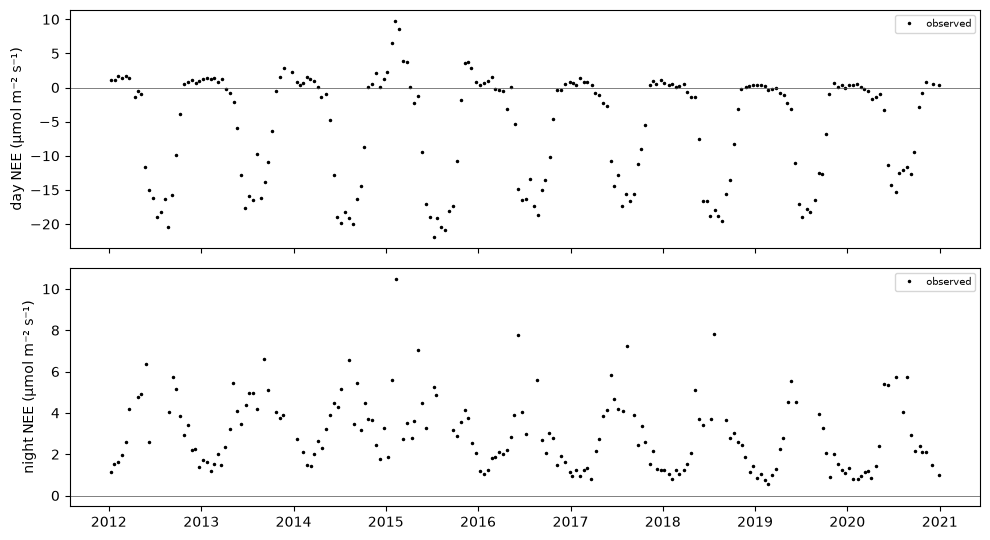

In [11]:
plots.plot_features(data);

### The weather

The SIPNET model requires weather (meteorological) data as an input. This is typically referred to as a model *driver*: it is exogenous data that *drives* the model. SIPNET is driven by the weather data on a 3-hourly time step. You can see the particular weather variables it requires below. The data is stored as an [xarray](https://docs.xarray.dev/en/stable/) dataset.

In [13]:
driver = ClimateDrivers.from_path(data.driver_path, time_zone="UTC").xarray
list(driver.data_vars)

['air_temperature',
 'soil_temperature',
 'photosynthetically_active_radiation',
 'precipitation',
 'vapor_pressure_deficit',
 'soil_vapor_pressure_deficit',
 'vapor_pressure',
 'wind_speed']

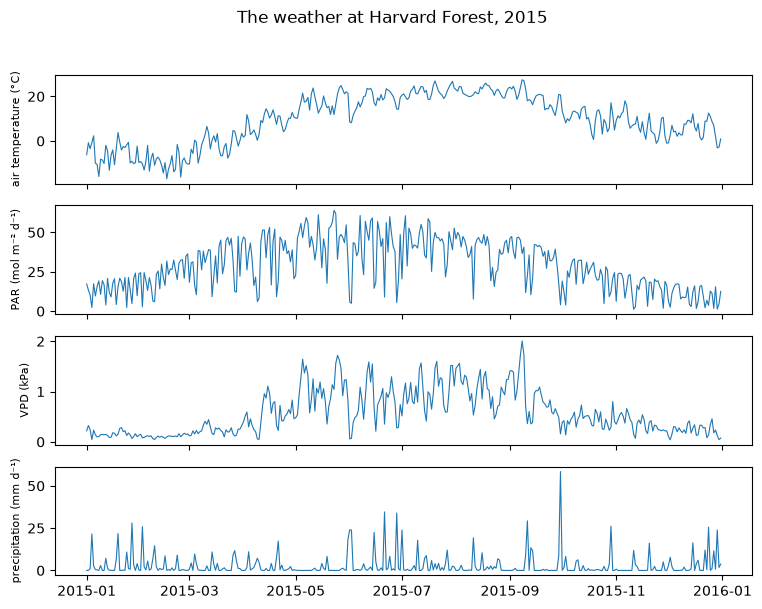

In [14]:
plot_weather(driver, YEAR)

## 3. The prior

SIPNET has a bunch of parameters. The inverse problem returned by `load_harvard_forest()` defines a prior distribution on 46 parameters. This set of parameters was assembled by (1) fixing parameters that are not directly related to our setup here (e.g., nitrogen cycle parameters) and (2) manually eliminating some exact nonidentifiability. This still leaves a large number of parameters, a prime candidate for data-driven parameter reduction algorithms. 

The prior distribution of each individual parameter is stored in `data.prior_table`.

In [15]:
data.prior_table.head(10)

,units,family,lower,upper,mean,sd,source
parameter,,,,,,,
photosynthetic_capacity,nmol g-1 s-1,log_normal,140.00,450.00,NaN,NaN,P2
respiration_share,1,logit_normal,0.04,0.20,NaN,NaN,P2
optimum_photosynthesis_temperature,degC,normal,NaN,NaN,22.0,2.5,P2
photosynthesis_temperature_range,degC,log_normal,17.00,31.00,NaN,NaN,"BETY psnTMin 2.5-97.5% (-6.5, 6.6) below psnTO..."
half_saturation_light,mol m-2 d-1,log_normal,4.60,26.30,NaN,NaN,BETY
vapor_pressure_deficit_slope,kPa-1,log_normal,0.02,0.12,NaN,NaN,BETY median 0.050; R interval
vapor_pressure_deficit_exponent,1,log_normal,1.00,3.00,NaN,NaN,"Niwot range [1, 3]; BETY 1.5, Braswell 2"
light_extinction_coefficient,1,log_normal,0.38,0.65,NaN,NaN,BETY attenuation widened by BETY leafCSpWt spr...
water_use_efficiency,mg g-1 kPa,log_normal,7.90,17.50,NaN,NaN,BETY


Most priors are log-normal, parameterized by the interval that holds 95% of their probability (`lower`
and `upper`). Section 9 gives more details.

### Sampling the prior

`problem.prior` stores a ProbPipe distribution representing the object $\pi_0(\theta)$. We show how to manipulate this object below.

In [21]:
prior = problem.prior
print(prior)

LogNormal(photosynthetic_capacity)·BijectorTransformedDistribution(respiration_share)·Normal(optimum_photosynthesis_temperature)·LogNormal(photosynthesis_temperature_range)·LogNormal(half_saturation_light)·LogNormal(vapor_pressure_deficit_slope)·LogNormal(vapor_pressure_deficit_exponent)·LogNormal(light_extinction_coefficient)·LogNormal(water_use_efficiency)·LogNormal(water_removal_fraction)·LogNormal(soil_water_holding_capacity)·BijectorTransformedDistribution(interception_evaporation_fraction)·BijectorTransformedDistribution(fast_flow_fraction)·LogNormal(snow_melt_rate)·LogNormal(aerodynamic_resistance_constant)·Normal(soil_resistance_intercept)·LogNormal(soil_resistance_slope)·LogNormal(leaf_on_growing_degree_days)·Normal(leaf_off_day)·LogNormal(leaf_on_growth)·BijectorTransformedDistribution(leaf_off_fall_fraction)·LogNormal(leaf_turnover_rate)·BijectorTransformedDistribution(leaf_allocation)·BijectorTransformedDistribution(wood_share_of_nonleaf_allocation)·BijectorTransformedDistr

Let's draw some samples from the prior. Observe that the parameters are all grouped under "theta". The reason for this is that the more general inverse problem we will consider later will contain another group of parameters as well. The code below shows how to access the values of particular parameters.

In [ ]:
with workflow_run(seed=0):
    prior_draws = sample(problem.prior, 2000)

print(prior_draws)

In [25]:
prior_draws["theta/photosynthetic_capacity"]

NumericArrayBatch(
    'theta/photosynthetic_capacity',
    levels={'sample': 2000},
    element=NumericArraySpec(shape=(), dtype=float64, support=positive),
)
  [273.24845094 422.9131429  179.3635181  ... 275.13365543 130.87320383
   284.06177026]

The raw array can be extracted from the ProbPipe object using `.raw`.

In [26]:
prior_draws["theta/photosynthetic_capacity"].raw

Array([273.24845094, 422.9131429 , 179.3635181 , ..., 275.13365543,
       130.87320383, 284.06177026], dtype=float64)

The `plots` module of this provides a function for visualizing one-dimensional marginal distributions.

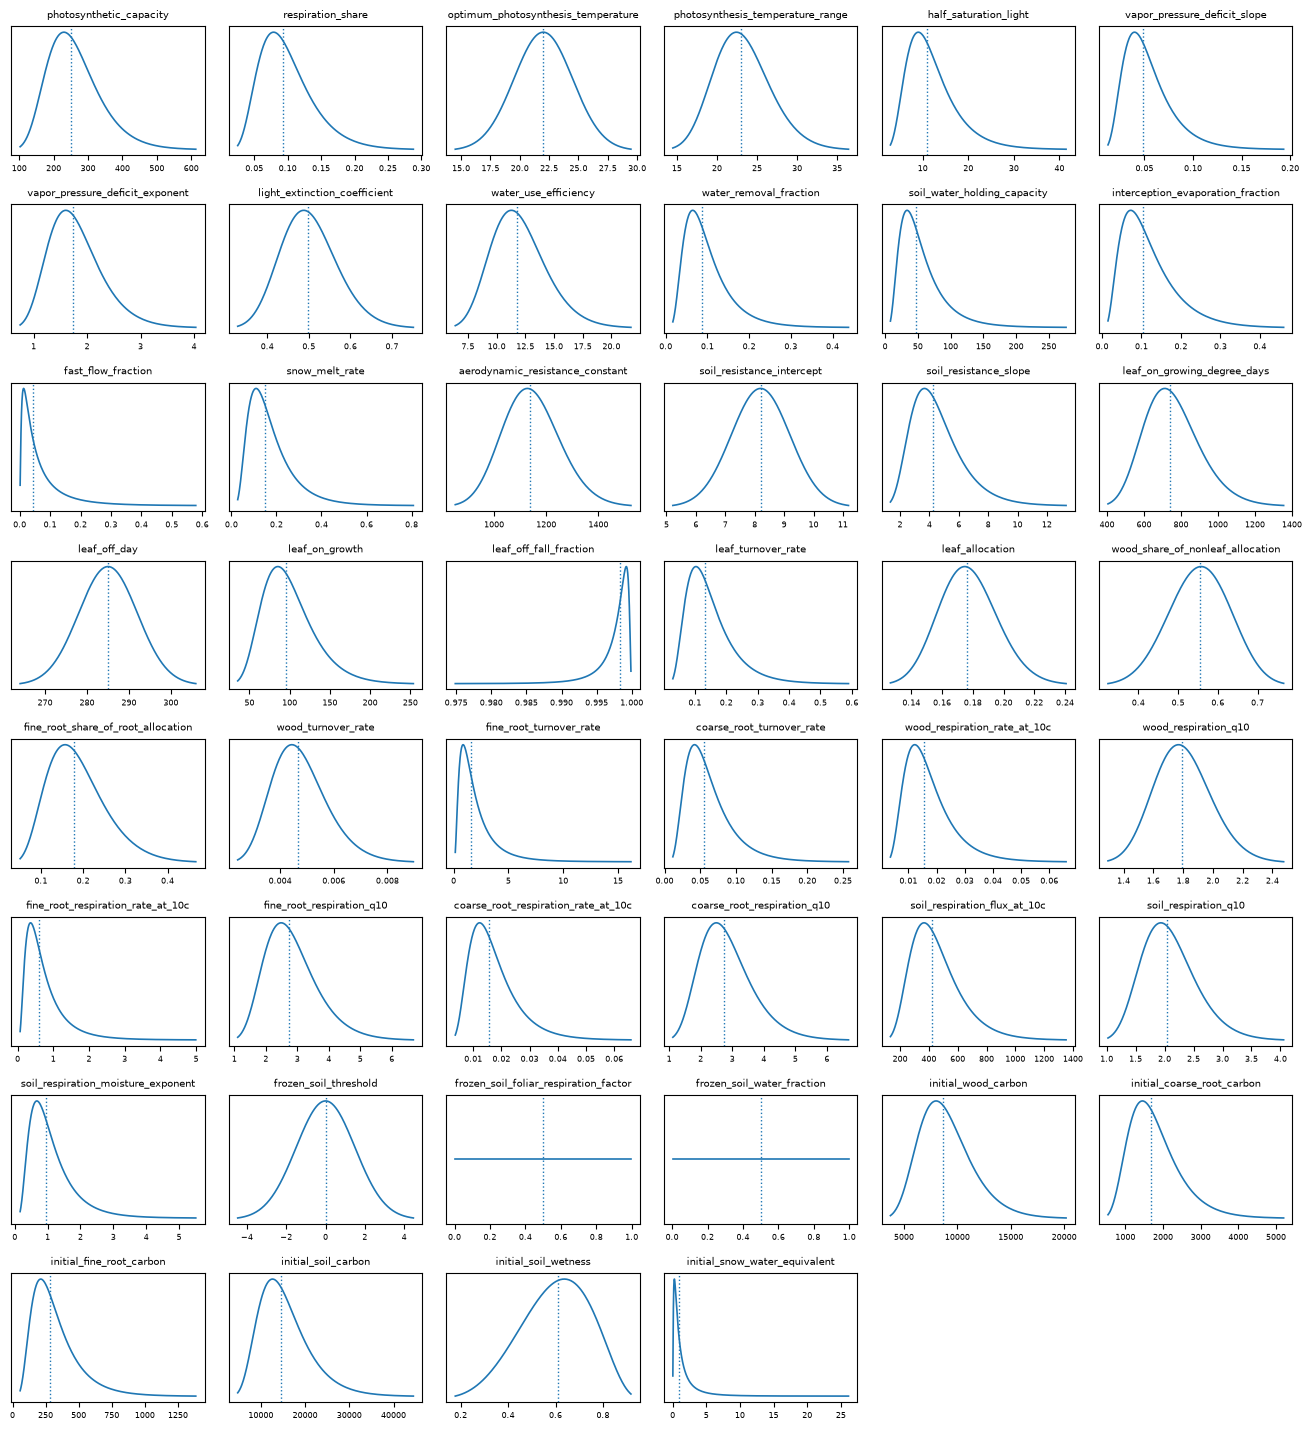

In [30]:
plots.plot_prior_marginals(problem);

ProbPipe's `summarize` command also gives a quick numeric summary of each marginal.

In [33]:
summarize(prior)

,mean,sd,median,q10,q90
theta/photosynthetic_capacity,2.65366003e+02,8.15916115e+01,2.50659889e+02,1.67011416e+02,3.60319850e+02
theta/respiration_share,9.76061117e-02,4.24189374e-02,9.04011611e-02,5.41975579e-02,1.56127112e-01
theta/optimum_photosynthesis_temperature,2.20334026e+01,2.52925370e+00,2.21835092e+01,1.89197572e+01,2.53461543e+01
theta/photosynthesis_temperature_range,2.31912895e+01,3.47571582e+00,2.30641055e+01,1.90489761e+01,2.77721361e+01
theta/half_saturation_light,1.20275461e+01,5.59029804e+00,1.08700506e+01,6.00665669e+00,1.99059252e+01
theta/vapor_pressure_deficit_slope,5.54244858e-02,2.61331772e-02,5.03357551e-02,2.81284473e-02,8.63618769e-02
theta/vapor_pressure_deficit_exponent,1.79560262e+00,5.01077330e-01,1.73430452e+00,1.18888625e+00,2.45262191e+00
theta/light_extinction_coefficient,5.01444389e-01,6.95471460e-02,4.93369893e-01,4.15500522e-01,6.00309321e-01
theta/water_use_efficiency,1.20153384e+01,2.54823058e+00,1.17348470e+01,8.99435286e+00,1.52207939e+01
theta/water_removal_fraction,1.00006550e-01,5.74491017e-02,8.80168107e-02,4.42433760e-02,1.83129316e-01


### Prior Density

The below code samples from the prior. Then it evaluates the prior log-density at those samples.

In [34]:
samples = sample(prior, 5)
log_density_samples = log_prob(prior, samples)

log_density_samples

NumericArrayBatch(
    'log (LogNormal(photosynthetic_capacity)·BijectorTransformedDistribution(respiration_share)·Normal(optimum_photosynthesis_temperature)·LogNormal(photosynthesis_temperature_range)·LogNormal(half_saturation_light)·LogNormal(vapor_pressure_deficit_slope)·LogNormal(vapor_pressure_deficit_exponent)·LogNormal(light_extinction_coefficient)·LogNormal(water_use_efficiency)·LogNormal(water_removal_fraction)·LogNormal(soil_water_holding_capacity)·BijectorTransformedDistribution(interception_evaporation_fraction)·BijectorTransformedDistribution(fast_flow_fraction)·LogNormal(snow_melt_rate)·LogNormal(aerodynamic_resistance_constant)·Normal(soil_resistance_intercept)·LogNormal(soil_resistance_slope)·LogNormal(leaf_on_growing_degree_days)·Normal(leaf_off_day)·LogNormal(leaf_on_growth)·BijectorTransformedDistribution(leaf_off_fall_fraction)·LogNormal(leaf_turnover_rate)·BijectorTransformedDistribution(leaf_allocation)·BijectorTransformedDistribution(wood_share_of_nonleaf_allocat

## 4. The forward model

The forward model $G$ maps parameters $\theta$ to predictions of the data $y$. It thus involves first running SIPNET, and then averaging SIPNET's output to produce a quantity comparable to the data. In the inverse problems literature, sometimes $G$ is referred to as the *parameter-to-observable* map, which is an apt description of what this object is.

The below code evaluates this map at $G(\theta_{\mathrm{median}})$ where $\theta_{\mathrm{median}}$ contains the prior median of each parameter.

In [ ]:
forward_model = problem.forward
prior_medians = quantile(prior, 0.5)

# TODO: why doesn't this work? It should
forward_model(prior_medians)

KeyError: 'photosynthetic_capacity'

At the prior medians, SIPNET follows the seasons, but in most years its summer uptake is too weak
(the day values do not dip as low as the data), and its night-time release outside summer is too
low.

In [ ]:
plot_predictions(data, prediction_at_medians, labels=["G(θ) at the prior medians"])

### Many parameter settings

`problem.forward` also takes a batch of settings, such as the `theta` of several prior draws. It
runs SIPNET once per setting, several at a time, and returns one row per setting:

In [ ]:
with workflow_run(seed=1):
    a_few_draws = sample(problem.prior, 8)

predictions = np.asarray(problem.forward(a_few_draws["theta"]).raw)
predictions.shape

Draws from the prior give different predictions, and some, like the one with a very large
summer night-time release, are far from the data: before seeing the data, a wide range of
behaviour is plausible.

In [ ]:
plot_predictions(data, predictions)

For parameters held in an array, one row per setting and columns in the order of `names`,
`problem.predicted_observations` does the same. The algorithms use this form.

### One parameter at a time

To see what a parameter does, move it through its prior with the others at their medians. Each
column of the figure moves one parameter through its prior's 2.5%, 25%, 50%, 75% and 97.5%
quantiles:

- The photosynthetic capacity sets how deep the summer uptake is, and, through the respiration of
  the leaves, part of the night-time release.
- With a small water-holding capacity, the soil dries out and the uptake collapses from July.
- The growing-degree days to leaf-on set when the uptake starts.
- The soil respiration rate at 10 °C sets the night-time release.

In [ ]:
varied = [
    "photosynthetic_capacity",
    "soil_water_holding_capacity",
    "leaf_on_growing_degree_days",
    "soil_respiration_flux_at_10c",
]
levels = [0.025, 0.25, 0.5, 0.75, 0.975]
settings = []
for name in varied:
    law = marginal(problem.prior, f"theta/{name}")
    for level in levels:
        setting = theta_median.copy()
        setting[names.index(name)] = float(quantile(law, level))
        settings.append(setting)
one_at_a_time = problem.predicted_observations(np.array(settings))
one_at_a_time.shape

In [ ]:
plot_one_at_a_time(data, one_at_a_time, varied, levels, YEAR)

Moving one parameter at a time cannot show how parameters act together. Two parameters can have
much the same effect, so that the data inform only a combination of them. Finding the
combinations that the data inform is what the algorithms in this repository do.

### When SIPNET fails

If SIPNET cannot run with some parameters, their row of predictions is NaN and a warning is
logged, so that one failure does not stop a batch. Here the second setting has a respiration share
of 1.5, outside its range $(0, 1)$. That makes SIPNET's maximum photosynthesis rate negative,
which pySIPNET refuses; the warning lists the SIPNET parameters of the failed run and the reason:

In [ ]:
impossible = theta_median.copy()
impossible[names.index("respiration_share")] = 1.5
failed = problem.predicted_observations(np.stack([theta_median, impossible]))
np.isnan(failed).all(axis=1)

### Inside the forward model

`problem.forward` hides its two steps. This subsection runs them by hand, for readers who want to
see SIPNET's own output; nothing later depends on it.

First, `calibration_to_sipnet` turns the 46 parameters into the 58 that SIPNET reads, adding the
12 that are fixed (section 9). A `SIPNETSimulator` runs SIPNET with them, and `run` returns every
output SIPNET writes, every three hours:

In [ ]:
sipnet_parameters = calibration_to_sipnet(medians, data.fixed_sipnet_parameters)
simulator = SIPNETSimulator(data.driver_path, data.fixed_sipnet_parameters)
outputs = simulator.run(sipnet_parameters)
print(len(sipnet_parameters), "SIPNET parameters;", len(outputs.data_vars), "outputs, such as")
print(", ".join(list(outputs.data_vars)[:8]))

`nee_rate` gives SIPNET's NEE in the data's units, one value per three-hour step. Through the
year, NEE is negative on summer days and positive at night and in winter; leaf carbon jumps when
the leaves come out in late spring and drops when they fall in autumn; the soil dries through the
summer.

In [ ]:
nee_rate = simulator.nee_rate(sipnet_parameters)
plot_sipnet_outputs(outputs, nee_rate, data.step_ends, YEAR)

Second, the averaging. `data.operator` is a matrix $A$ with one row per data value: multiplying
SIPNET's NEE by it averages each value's hours. So $G(\theta) = A\, x(\theta)$, where $x(\theta)$
is SIPNET's NEE every three hours:

In [ ]:
A = data.operator
np.allclose(A @ nee_rate, prediction_at_medians)

The figure shows the averaging for the first half of July. The day value averages many more
windows than the night value: summer nights are short, and many night-time measurements are
gap-filled rather than measured, so they are left out.

In [ ]:
plot_averaging(data, nee_rate, prediction_at_medians, YEAR)

## 5. The likelihood

The predictions never match the data exactly: the measurements have errors, and SIPNET is a
simplified model of the forest. The likelihood describes the gap as Gaussian noise,

$$
y_i = G_i(\theta) + \epsilon_i, \qquad \epsilon_i \sim \mathcal N(0, v_i),
$$

independently for each value $i$. The noise variance $v_i$ is 8 (µmol m⁻² s⁻¹)² for day values and
1.5 for night values: daytime fluxes are larger, and so are their errors. `problem.likelihood` is
this model, and `noise_variances()` gives $v$:

In [ ]:
likelihood = problem.likelihood
noise_variance = np.asarray(likelihood.noise_variances())
pd.Series(noise_variance).groupby(data.feature_classes).first()

`pointwise_log_prob` gives each value's log-likelihood, $\log \mathcal N(y_i \mid G_i(\theta),
v_i)$, at a parameter setting. It runs SIPNET once:

In [ ]:
log_likelihood = np.asarray(likelihood.pointwise_log_prob({"theta": medians}, y))
log_likelihood.shape, log_likelihood.sum()

### The learning rate

One more ingredient. The model's errors in neighbouring half-months are related: if SIPNET
underestimates the uptake in early July, it probably does in late July too. So the 400 values carry
less information than 400 independent measurements would, and treating them as independent would
make the posterior too confident.

To correct for this, each value's log-likelihood is multiplied by a **learning rate**
$\eta_i < 1$. It is chosen so that the data count as much as about three independent values per
year for each class (section 9 has the formula). `problem.learning_rate["nee"]` holds it:

In [ ]:
eta = problem.learning_rate["nee"]
pd.Series(eta).groupby(data.feature_classes).first()

Multiplying a Gaussian log-likelihood by $\eta_i$ has the same effect on $\theta$ as dividing the
noise variance by $\eta_i$. So the learning rate widens the noise, here by a factor of 7 to 8 in
variance. `problem.noise_variance()` gives the widened variances, $v_i / \eta_i$:

In [ ]:
widened_variance = problem.noise_variance()
pd.Series(np.sqrt(widened_variance)).groupby(data.feature_classes).first()

At the prior medians, most of the gap between the data and the predictions lies within two
standard deviations of the noise. But the gap runs in long stretches of the same sign: the
related errors that the learning rate accounts for.

In [ ]:
plot_residuals(data, y - prediction_at_medians, noise_variance, widened_variance)

## 6. Putting it together

### The prior predictive

The prior and the likelihood together describe how data could arise: draw $\theta$ from the
prior, run SIPNET, and add noise. `problem.model` is this description, and
`sample(problem.model, n)` follows it $n$ times, running SIPNET once per draw. The learning rate
plays no part here; it only matters when we condition on the data.

In [ ]:
with workflow_run(seed=2):
    replications = sample(problem.model, 200)

replicated_nee = np.asarray(replications["nee"].raw)
print(replicated_nee.shape, "with", np.isnan(replicated_nee).any(axis=1).sum(), "failed runs")

If the prior is reasonable, the data should look like a typical draw. The fraction of values
inside the middle 90% of the draws, by class:

In [ ]:
completed = replicated_nee[np.isfinite(replicated_nee).all(axis=1)]  # leave out failed runs
lower, upper = np.quantile(completed, [0.05, 0.95], axis=0)
inside = (y >= lower) & (y <= upper)
pd.Series(inside).groupby(data.feature_classes).mean()

The bands are wide, as a prior's should be, and they hold most of the data. Two things stand out:
in most summers the observed uptake lies near the lower edge of the bands, and a few winter day
values in early 2015 lie above every draw.

In [ ]:
plots.plot_features(data, replicated_nee);

### The posterior

With the learning rate, the log-posterior is, up to a constant,

$$
\log \pi(\theta \mid y) = \log \pi(\theta)
+ \sum_{i=1}^{400} \eta_i \log \mathcal N\!\left(y_i \mid G_i(\theta), v_i\right)
+ \text{const}.
$$

At the prior medians, adding up the pieces from sections 3 and 5:

In [ ]:
log_prior = float(log_prob(problem.prior, {"theta": medians}).raw)
log_prior + np.sum(eta * log_likelihood)

`problem.condition` gives the posterior as an object. Its `method` says how to compute it. The
algorithm tutorials use methods that draw samples from the posterior. `method="unnormalized"`
computes nothing: it returns the posterior as an unnormalized density, the object that every
inference method starts from. Its density at the medians matches the sum above:

In [ ]:
posterior = problem.condition(method="unnormalized")
float(unnormalized_log_prob(posterior, {"theta": medians}).raw)

Drawing samples from this posterior is hard: each evaluation runs SIPNET, and there are 46
parameters. The algorithms in this repository reduce the work by finding the few combinations of
parameters that the data inform. The README's sections "The first algorithm" and "Comparing
algorithms" show how to run them.

## 7. Learning noise scales

So far the noise variances, 8 by day and 1.5 by night, were fixed. They are a judgement, and the
data can say whether the noise is larger or smaller. To let them, multiply each class's variance by
an unknown **noise scale**, $s^2_{\mathrm{day}}$ or $s^2_{\mathrm{night}}$, and give each scale a
prior:

$$
\epsilon_i \sim \mathcal N\!\left(0,\; s^2_{k(i)}\, v_i\right),
$$

where $k(i)$ is the class of value $i$. `scales="inferred"` loads this version of the problem:

In [ ]:
problem_with_scales = load("harvard_forest", scales="inferred")
with workflow_run(seed=3):
    draws_with_scales = sample(problem_with_scales.prior, 4)

np.asarray(draws_with_scales["s2_day"].raw), np.asarray(draws_with_scales["s2_night"].raw)

The prior now draws the two scales along with $\theta$. Each scale's prior is inverse-gamma with
shape 2 and scale 1.678, so its median is 1: a priori, the fixed variances are right. Its long
right tail lets the data raise the noise well above them.

In [ ]:
scale_law = marginal(problem_with_scales.prior, "s2_day")
scale_grid = np.linspace(0.05, 6, 300)
on_grid = NumericArrayBatch(scale_grid, level_names="grid", label="grid")
scale_density = np.exp(np.asarray(log_prob(scale_law, on_grid)))
plot_density(
    scale_grid,
    scale_density,
    float(quantile(scale_law, 0.5)),
    "$s^2_k$",
    "The prior of each noise scale",
)

The likelihood now needs the scales as well as $\theta$. For example, the noise variances with
the day noise doubled:

In [ ]:
scaled = problem_with_scales.likelihood.noise_variances({"s2_day": 2.0, "s2_night": 1.0})
np.unique(np.asarray(scaled))

## 8. Coordinates

The parameters have different units and ranges: the photosynthetic capacity is in the hundreds, a
respiration share is near 0.1, and many are bounded. The algorithms compare directions in
parameter space, so they need every parameter on the same scale. They use three coordinate
systems:

- **constrained**, $\theta$: each parameter in its own units and range;
- **unconstrained**, $z$: each parameter mapped to the whole real line, by the logarithm for a
  positive parameter, the logit for one between 0 and 1, and unchanged for one that can take any
  value;
- **whitened**, $\xi$: $z$ shifted and scaled so that, under the prior, $\xi$ has mean 0 and
  covariance $I$.

`problem.coordinates` moves between them. Its maps act on arrays with one row per setting:

In [ ]:
coordinates = problem.coordinates
z_draws = coordinates.bijection.to_unconstrained(theta_draws)
xi_draws = coordinates.whiten(z_draws)
print("largest |mean| of ξ:", np.abs(xi_draws.mean(axis=0)).max().round(3))

`whitened_from_parameters` and `parameters_from_whitened` go directly between $\theta$ and $\xi$:

In [ ]:
np.allclose(coordinates.parameters_from_whitened(xi_draws), theta_draws)

The prior draws of a log-normal parameter and a logit-normal one, in each system: each becomes
normal in $z$, and standard normal in $\xi$.

In [ ]:
systems = {"θ": theta_draws, "z": z_draws, "ξ": xi_draws}
plot_coordinates(systems, names, ["photosynthetic_capacity", "respiration_share"])

## 9. Mathematical details

This section states the problem in full.

### The posterior

With the learning rates $\eta_i$ and, when they are inferred, the noise scales $s^2_k$, the
posterior is

$$
\pi_\eta(\theta, s^2 \mid y) \;\propto\; \pi(\theta)\, \pi(s^2)
\prod_{i=1}^{n} \mathcal N\!\left(y_i \;\middle|\; G_i(\theta),\; s^2_{k(i)}\, v_i\right)^{\eta_i},
$$

with $n = 400$ data values, $\theta \in \mathbb R^{46}$, $v_{\mathrm{day}} = 8$,
$v_{\mathrm{night}} = 1.5$ and, independently for each class, $s^2_k \sim \mathrm{IG}(2, 1.678)$
(that is, $1/s^2_k$ has a gamma law with shape 2 and rate 1.678). With fixed scales,
$s^2_{\mathrm{day}} = s^2_{\mathrm{night}} = 1$ and $\pi(s^2)$ drops out.

### From SIPNET's parameters to the calibration parameters

pySIPNET sets 58 SIPNET parameters. Twelve are fixed:

- eight have no effect on NEE at this site under SIPNET's standard model options;
- three can be changed together with others without changing NEE at all, so only the
  combinations that matter are calibrated;
- one, the initial leaf area, is zero because each run starts on 1 January, when the forest has
  no leaves.

`data.fixed_sipnet_parameters` holds their values, and `data/harvard_forest/sipnet_fixed.csv`
gives the reason for each:

In [ ]:
pd.Series(data.fixed_sipnet_parameters, name="value")

The other 46 are the calibration parameters $\theta$. Most are SIPNET parameters under the same
name. The rest change variables (in `lsmas.parameters`), so that each parameter's prior can be
stated on its own:

- **Photosynthesis.** NEE depends on SIPNET's four photosynthesis parameters only through two
  combinations, the photosynthetic capacity $P$ and the share $\rho$ of it respired by leaves.
  $P$ and $\rho$ are calibrated.
- **Photosynthesis temperatures.** The optimum $T_{\mathrm{opt}}$ and the range $\Delta$, with
  $T_{\min} = T_{\mathrm{opt}} - \Delta$, so that $T_{\min} < T_{\mathrm{opt}}$ for any values.
- **Respiration.** Each rate is stated at 10 °C, $k_{10} = k\, Q_{10}$, rather than SIPNET's
  rate $k$ at 0 °C.
- **Allocation of growth.** Leaves take a share $\ell$, wood a share $w$ of the rest, fine roots
  a share $f$ of what remains, and coarse roots the remainder; any shares in $(0, 1)$ are valid.
- **Initial pools.** The initial wood, coarse-root and fine-root carbon are each an amount, in
  g C m⁻², rather than SIPNET's total and fractions.

### The prior

$\pi(\theta) = \prod_{j=1}^{46} \pi_j(\theta_j)$, each factor in one of four families:

- **log-normal**, $\log \theta_j \sim \mathcal N(\mu_j, \sigma_j^2)$, with $\mu_j =
  \tfrac12(\log \ell_j + \log u_j)$ and $\sigma_j = (\log u_j - \log \ell_j) / (2 \times 1.96)$,
  so that $[\ell_j, u_j]$ (`lower`, `upper`) holds 95% of the probability;
- **logit-normal**, the same on the logit scale, for a parameter in $(0, 1)$;
- **normal**, with the table's `mean` and `sd`;
- **uniform** on $[\ell_j, u_j]$.

### The observation operator

SIPNET's NEE every three hours is $x(\theta) \in \mathbb R^S$, with $S = 37{,}992$ steps. Data
value $i$ averages the set $S_i$ of usable three-hour windows of its half-month and class, so

$$
A_{is} = \begin{cases} 1/|S_i| & s \in S_i, \\ 0 & \text{otherwise,} \end{cases}
\qquad G(\theta) = A\, x(\theta).
$$

### The learning rate

For class $k$, with $n_k$ values spread over $M_k$ calendar months and $c = 3$ effective
observations per class-year,

$$
\eta_k = \min\!\left(1,\; \frac{c\, M_k}{12\, n_k}\right).
$$

Computed from the data table, it matches `problem.learning_rate`:

In [ ]:
calendar_month = data.features["year"] * 12 + data.features["month"]
by_class = data.features.assign(calendar_month=calendar_month).groupby("class")
learning_rates = by_class.agg(n_k=("nee", "size"), M_k=("calendar_month", "nunique"))
learning_rates["3 M_k / (12 n_k)"] = 3 * learning_rates["M_k"] / (12 * learning_rates["n_k"])
learning_rates["problem.learning_rate"] = pd.Series(eta).groupby(data.feature_classes).first()
learning_rates

### The tempered noise covariance

As a function of $\theta$,

$$
\mathcal N\!\left(y_i \mid G_i(\theta), s^2_{k(i)} v_i\right)^{\eta_i}
\;\propto\; \mathcal N\!\left(y_i \;\middle|\; G_i(\theta), \frac{s^2_{k(i)} v_i}{\eta_i}\right),
$$

where the constant depends on $s^2$ but not on $\theta$. So for fixed noise scales, the posterior
of $\theta$ is the prior times a Gaussian likelihood with covariance

$$
\Gamma = \operatorname{diag}\!\left(\frac{s^2_{k(i)}\, v_i}{\eta_i}\right),
$$

which `problem.noise_variance()` returns. When the scales are inferred, the constant matters: the
posterior of $s^2$ must be computed from the tempered density, not from $\Gamma$.

### What the learning rate does

Along one line through parameter space, with every parameter but the photosynthetic capacity at
its median, the log-posterior with and without the learning rate is, up to constants,

$$
\log \pi_j(\theta_j) + \sum_{i} \eta_i \log \mathcal N\!\left(y_i \mid G_i(\theta), v_i\right)
\quad\text{and}\quad
\log \pi_j(\theta_j) + \sum_{i} \log \mathcal N\!\left(y_i \mid G_i(\theta), v_i\right).
$$

The grid is coarse across the prior and fine near the peak, which is narrow:

In [ ]:
name = "photosynthetic_capacity"
law = marginal(problem.prior, f"theta/{name}")


def log_densities_along_line(values):
    """The log prior and posteriors, up to constants, along the line through the medians."""
    theta = np.tile(theta_median, (len(values), 1))
    theta[:, names.index(name)] = values
    residual = y - problem.predicted_observations(theta)
    log_likelihood = -0.5 * (residual**2 / noise_variance + np.log(2 * np.pi * noise_variance))
    log_prior = np.asarray(
        log_prob(law, NumericArrayBatch(values, level_names="grid", label="grid"))
    )
    return {
        "prior": log_prior,
        "posterior without learning rate": log_prior + log_likelihood.sum(axis=1),
        "posterior with learning rate": log_prior + (eta * log_likelihood).sum(axis=1),
    }


coarse = np.linspace(float(quantile(law, 0.005)), float(quantile(law, 0.995)), 21)
peak = coarse[np.argmax(log_densities_along_line(coarse)["posterior with learning rate"])]
half_width = 1.5 * (coarse[1] - coarse[0])
values = np.union1d(coarse, np.linspace(peak - half_width, peak + half_width, 61))
log_densities = log_densities_along_line(values)

Both posteriors are far narrower than the prior. The one with the learning rate is about three
times wider than the one without it ($1/\sqrt{\eta} \approx 2.8$). This is a slice with every
other parameter fixed, not the posterior of the photosynthetic capacity alone, which is generally
wider.

In [ ]:
plot_slice(values, log_densities, (peak - half_width, peak + half_width), name)

### Symbols and code

| Symbol | Meaning | In code |
|---|---|---|
| $y$ | the 400 data values | `problem.data["nee"]`, `data.features` |
| $\theta$ | the 46 calibration parameters | `problem.coordinates.names` |
| $\pi(\theta)$ | the prior | `problem.prior`, `data.prior_table` |
| $x(\theta)$ | SIPNET's NEE every three hours | `SIPNETSimulator(...).nee_rate(...)` |
| $A$ | the observation operator | `data.operator` |
| $G(\theta) = A\, x(\theta)$ | the forward model | `problem.forward`, `problem.predicted_observations` |
| $v_k$ | the noise variances | `problem.likelihood.noise_variances()` |
| $\eta$ | the learning rates | `problem.learning_rate["nee"]` |
| $\Gamma$ | the tempered noise covariance | `problem.noise_variance()` |
| $s^2_k$ | the noise scales | `load("harvard_forest", scales="inferred")` |
| $z$, $\xi$ | unconstrained and whitened coordinates | `problem.coordinates` |
| $\pi_\eta(\theta \mid y)$ | the posterior | `problem.condition(method=...)` |